<a href="https://colab.research.google.com/github/yamellinares/lab-agile-planning/blob/main/ejercicio1_ml_pt2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lista 1 de Ejercicios
Objetivo:
Estos ejercicios pretenden poner en práctica la habilidad del estudiante para crear un modelo sencillo pero completo end2end con la librería sklearn mediante el uso de transformadores ad hoc, una batería de algoritmos y un tuneado de parámetros.

Tarea del estudiante:
Lee detenidamente las siguientes instrucciones
En cada trozo de código debes responder a la pregunta formulada, asegurándote de que el resultado queda guardado en la(s) variable(s) indicadas que, por defecto, vienen inicializadas a None. Puedes usar variables intermedias siempre que el resultado final del cálculo quede guardado exactamente en la variable que indica el enunciado (debes reemplazar None el código necesario, pero nunca cambiar el nombre de las variables ya creadas).

Después de cada apartado verás celdas de control. Ejecútalas todas y no modifiques su código. Éstas te dirán si tu solución va por buen camino. Así, si la solución es incorrecta, verás un error indicando cuál es el assert que tu solución no pasa. Además de esas pruebas, se realizarán algunas más (ocultas) a la hora de puntuar el ejercicio.

Una vez finalizada la actividad, guarda tu fichero, ciérralo con File -> Close and Halt, y después vuélvelo a abrir y ejecútalo completo pinchando en Cell -> Run All Cells, y asegúrate de que no se lanza ningún error. De esta manera comprobarás que no has olvidado nada y que es posible ejecutarlo completo desde 0 y sin errores. Finalmente, TODO EL CÓDIGO DEBE ESTAR EJECUTADO (EN ORDEN) EN EL FICHERO QUE ENTREGÁIS.

RECUERDA SUBIR CADA UNO DE LOS FICHEROS .ipynb TAL CUAL (sueltos), SIN COMPRIMIR Y SIN CAMBIARLES EL NOMBRE. Los ficheros subidos deben tener exactamente el mismo nombre de fichero que tenían cuando los recibiste. No subas ningún PDF ni ningún fichero ZIP ni nada similar. La plataforma ya los separa automáticamente en carpetas que traen el nombre y apellidos del alumno, por lo que NO es necesario que lo pongas en ninguna parte.

IMPORTANTE: No modifiquéis los assert

Evaluación:
Esta tarea tiene una puntuación de 6 puntos. La suma de todos los puntos obtenidas de todos los notebooks se ponderará sobre 10 puntos para computar la nota final del estudiante.

Parte 0: Inicialización
En esta parte, simplemente cargamos las librerías que vamos a utilizar y establecemos una semilla para controlar la reproducibilidad del ejercicio.

In [3]:
""" Librerías """

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sys

sns.set_style('darkgrid')
np.set_printoptions(precision=2)
warnings.filterwarnings("ignore")

import sklearn
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, Binarizer, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, PowerTransformer
from sklearn.impute import SimpleImputer, KNNImputer

from sklearn.feature_selection import SelectKBest, chi2, RFE
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

from sklearn.model_selection import KFold, ShuffleSplit, LeaveOneOut, StratifiedKFold
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

""" Semilla """

seed = 99

Comprobamos que tenemos el entorno virtual correctamente creado en la siguiente celda. Si fallase alguno de los asserts, significaría que no tenemos la versión correcta:

In [4]:
assert sys.version[0:4] == '3.10'
assert sklearn.__version__ == '1.5.2'
assert matplotlib.__version__ == '3.9.2'
assert sns.__version__ == '0.13.2'
assert pd.__version__ == '2.2.3'
assert np.__version__ == '2.1.2'

AssertionError: 

Parte 1: Lectura y transformación de datos (1.5 puntos)
En esta parte, principalmente, cargaremos los datos de un repositorio git y realizaremos una breve limpieza de los datos para conseguir un dataframe listo.

Utilizaremos dos variables: data, para la lectura original del fichero, y df que será con la que avancemos en la tarea.

In [5]:
data = pd.read_csv('https://raw.githubusercontent.com/eduardofc/data/main/titanic-2.csv')

print(f'Número de filas: {data.shape[0]}, Número de columnas:{data.shape[1]}')
df = data.copy()
df.head()

Número de filas: 891, Número de columnas:13


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr


Se pide en esta celda, crear una columna adicional, llamada hasCabin, que tome valor 0 si la columna Cabin es nula, y 1 si no lo es. Después, eliminar las columnas PassengerId, Name, Cabin y Ticket.

In [6]:
### BEGIN SOLUTION
# Creo la columna 'hasCabin', si Cabin es nula (NaN), asigno 0, si no es nula, asigno 1
df['hasCabin'] = df['Cabin'].notna().astype(int)

# Elimino las columnas PassengerId, Name, Cabin y Ticket
df.drop(columns=['PassengerId', 'Name', 'Cabin', 'Ticket'], inplace=True)

df.head()

### END SOLUTION

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,hasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,0


Celda de control:

In [7]:
key_cols = ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'hasCabin']

assert sum([x in key_cols for x in df.columns]) == 10
assert len(df.columns) == 10
assert (df.groupby('hasCabin').size()[0], df.groupby('hasCabin').size()[1]) == (687, 204)

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,hasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,0


Se pide en esta celda, eliminar los dos registros cuyo valor Embarked es nulo. Tras ello, eliminar todos los duplicados.

In [8]:
### BEGIN SOLUTION
# Elimino los registros nulos en 'Embarked'
df = df.dropna(subset=['Embarked'])

# Elimino todos los registros duplicados
df = df.drop_duplicates()

print(f'Número de filas: {df.shape[0]}, Número de columnas:{df.shape[1]}')

age_nulls = df.Age.isnull().sum()
print(f"NaN en Age: {age_nulls}")

duplicated = df.duplicated().sum()
print(f"Filas duplicadas: {duplicated}")


### END SOLUTION

Número de filas: 788, Número de columnas:10
NaN en Age: 109
Filas duplicadas: 0


Celda de control:

In [9]:
assert len(df) == 788
assert df.Age.isnull().sum() == 109
assert df.duplicated().sum() == 0

In [10]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,109
SibSp,0
Parch,0
Fare,0
Embarked,0
Title,0
hasCabin,0


En esta celda se pide, almacenar en una variable llamada col_transformer un ColumnTransformer que lleve en orden:

Un KNN Imputer de 5 vecinos con métrica nan_euclidean y pesos uniformes, para Pclass, Age, SibSp, Fare.
Un OneHotEncoder para las variables categóricas:
Sex (con la opción drop=if_binary),
Embarked (con la opción drop=first),
Parch (con la opción de handle_unknown=ignore) y,
Title con las categorías Mr, Mrs y Miss (y con la opción de handle_unknown=ignore).
El ColumnTransfomer tiene una opción llamada reminder que asignaremos a valor passthrough en este ejercicio. Se recomienda al estudiante investigar lo que significa en la documentación. Por defecto, la opción drop es la que ColumnTransformer tiene activada.

image.png

Nota: Para que la celda de control no falle, es importante poner en orden tanto los transformadores como las variables.

In [11]:
### BEGIN SOLUTION

col_transformer = ColumnTransformer([
        # KNN Imputer de 5 vecinos
        ('knn_imputer', KNNImputer(n_neighbors=5, metric='nan_euclidean', weights='uniform'),
         ['Pclass', 'Age', 'SibSp', 'Fare']),
        # OneHotEncoder para variables categóricas
        ('sex_encoder', OneHotEncoder(drop='if_binary'), ['Sex']),
        ('embarked_encoder', OneHotEncoder(drop='first'), ['Embarked']),
        ('parch_encoder', OneHotEncoder(handle_unknown='ignore'), ['Parch']),
        ('title_encoder', OneHotEncoder(categories=[['Mr', 'Mrs', 'Miss']], handle_unknown='ignore'), ['Title'])
    ],
    # Remainder = passthrough para pasar automáticamente el resto de columnas no especificadas en el ColumnTransformer
    remainder='passthrough'
)

### END SOLUTION

ctransformed = col_transformer.fit_transform(df)
print(col_transformer.get_feature_names_out())
ctransformed[:3]

current_shape = ctransformed.shape
print(f" Forma: {current_shape}")
print()

row_1 = np.round(ctransformed[1], 2)
print(f" Fila 1: {row_1}")
print()

row_100 = np.round(ctransformed[100], 2)
print(f" Fila 100: {row_100}")

['knn_imputer__Pclass' 'knn_imputer__Age' 'knn_imputer__SibSp'
 'knn_imputer__Fare' 'sex_encoder__Sex_male'
 'embarked_encoder__Embarked_Q' 'embarked_encoder__Embarked_S'
 'parch_encoder__Parch_0' 'parch_encoder__Parch_1'
 'parch_encoder__Parch_2' 'parch_encoder__Parch_3'
 'parch_encoder__Parch_4' 'parch_encoder__Parch_5'
 'parch_encoder__Parch_6' 'title_encoder__Title_Mr'
 'title_encoder__Title_Mrs' 'title_encoder__Title_Miss'
 'remainder__Survived' 'remainder__hasCabin']
 Forma: (788, 19)

 Fila 1: [ 1.   38.    1.   71.28  0.    0.    0.    1.    0.    0.    0.    0.
  0.    0.    0.    1.    0.    1.    1.  ]

 Fila 100: [ 3.   22.    0.    7.78  1.    0.    1.    1.    0.    0.    0.    0.
  0.    0.    1.    0.    0.    1.    0.  ]


Celda de control:

In [12]:
assert ctransformed.shape == (788, 19)
assert sum(np.round(ctransformed[1],2) == [1., 38., 1., 71.28, 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 1., 1.]) == 19
assert (sum(np.round(ctransformed[100],2) == [3., 22.0, 0., 7.78, 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0.]) >= 18) \
    or (sum(np.round(ctransformed[100],2) == [3., 19.2, 0., 7.78, 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0.]) >= 18)

Parte 2: Selección de modelo (1.5 puntos)
En esta parte, evaluaremos diversos estimadores (algoritmos, transformadores+algoritmos) con el objeto de predecir la variable objetivo (Survived) y estudiar su comportamiento.

In [13]:
models = []
models.append(('LR', LogisticRegression(random_state=seed)))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('DTC', DecisionTreeClassifier(random_state=seed)))
models.append(('NB', GaussianNB()))
models.append(('RFC', RandomForestClassifier(random_state=seed)))
models.append(('SVM', SVC()))

X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'hasCabin']]
y = df['Survived']

def boxplots_algorithms(results, names):

    plt.figure(figsize=(9, 3))
    plt.boxplot(results)
    plt.xticks(range(1,len(names)+1), names)
    plt.show()

En esta celda se pide, realizar un bucle que calcule, para cada algoritmo de la variable models,

Un pipeline que realice:

El ColumnTransformer diseñado anteriormente
Un RobustScaler a continuación y, finalmente,
Evalue cada algoritmo con scoring='accuracy'.
Una validación cruzada:

Tipo KFolds, con 10 folders, y
Aleatorio con semilla seed.
En cada iteración del bucle, almacenar el resultado de cada validación cruzada en una variable results y los nombres de cada algoritmo en una variable names.

Finalmente, usaremos la función boxplots_algorithms para dibujar los resultados.

Nota: Quizá os haya llamado la atención el RobustScaler. En realidad, no sería muy necesario introducirlo. Sin embargo, se deja por motivos didácticos, para que practiquéis y veáis que también se pueden combinar en un mismo pipeline, tanto transformadores sencillos, como columnTransformers. Por otra parte, fuera de la evaluación, dejo al estudiante que practique quitando el RobustScaler y explore las diferencias. Además, también dejo al estudiante que explore las diferencias de aplicar o no el passthrogh comentado anteriormente.

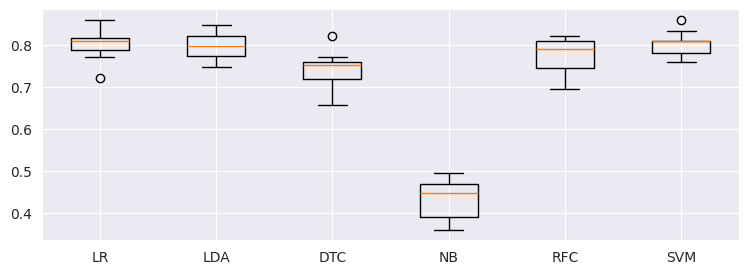

6
6
Fold 5 actual: [np.float64(0.8), np.float64(0.8), np.float64(0.7), np.float64(0.49), np.float64(0.7), np.float64(0.77)]
Opción 1:      [0.8, 0.8, 0.7, 0.49, 0.7, 0.77]
Opción 2:      [0.8, 0.8, 0.68, 0.49, 0.71, 0.77]
✅ Test: PASA


In [14]:
results = []
names = []

### BEGIN SOLUTION

# Creo el bucle
for name, model in models:
    # Creo el pipeline:
    pipeline = Pipeline([
        ('col_transformer', col_transformer),
        ('scaler', RobustScaler()),
        ('model', model)
    ])

# Defino validación cruzada tipo KFolds = 10 folders
    kfold = KFold(n_splits=10, shuffle=True, random_state=seed)

    # Ejecuto validación cruzada y evalúo scoring='accuracy'
    cv_results = cross_val_score(pipeline, X, y, cv=kfold, scoring='accuracy')

    # Almaceno resultados
    results.append(cv_results)
    names.append(name)

### END SOLUTION

boxplots_algorithms(results, names)

print(len(results))
print(len(models))

# Extraigo fold 5 de cada resultado
fold_5_values = [np.round(x[4], 2) for x in results]
print(f"Fold 5 actual: {fold_5_values}")

# Opciones esperadas
opt1 = [0.80, 0.80, 0.70, 0.49, 0.70, 0.77]
opt2 = [0.80, 0.80, 0.68, 0.49, 0.71, 0.77]

print(f"Opción 1:      {opt1}")
print(f"Opción 2:      {opt2}")

# Test
test_ok = (fold_5_values == opt1) or (fold_5_values == opt2)
print(f"✅ Test: {'PASA' if test_ok else 'FALLA'}")

Celda de control:

In [15]:
assert len(results) == len(models)
assert ([np.round(x[4],2) for x in results] == [0.80, 0.80, 0.70, 0.49, 0.70, 0.77]) or ([np.round(x[4],2) for x in results] == [0.80, 0.80, 0.68, 0.49, 0.71, 0.77])

Parte 3: Tuneado del modelo (3 puntos)
En esta parte, elegiremos un modelo compuesto por transformaciones y un algoritmo seleccionado. En concreto, probaremos diferentes parametrizaciones del algoritmo para obtener la mejor métrica.

En esta celda se pide, realizar un tuneado del RandomForestClassifier con GridSearchCV para estimar cuál es la mejor configuración paramétrica entre:

10 y 20 estimadores,
maximo número de variables estimado con los algoritmos sqrt y log2,
máxima profundidad 4,5,6,7 u 8,
criterio para medir la calidad del split entre gini o entropy.
El modelo final, entrenado con GridSearchCV y las variables (X, y), se almacenará en una variable llamada grid_model.

El entrenamiento del modelo se hará con un StratifiedKfolds de 10 folders aleatorio.

Se utilizará el mismo ColumnTransformer que en el apartado anterior y, a continuación, el algoritmo de Random Forest (sin RobustScaler).

Nota 1: No olvidar usar semilla cuando aplique.

Nota 2: En este ejercicio no haremos ningún train-test split.

Nota 3: El diccionario de parámetros, cuando es un pipeline, hay que definir para cuál de las fases del pipeline deben aplicarse los parámetros. En este ejercicio, los parámetros son del algoritmo, por lo que todos los parámetros deben llevar el prefijo "model " y dos guiones bajos "_" (donde model es el nombre del algoritmo definido en el pipeline -es recomendable investigar esta parte-).

In [16]:
grid_model = None

### BEGIN SOLUTION

# Creo pipeline con ColumnTransformer y RandomForestClassifier
pipeline = Pipeline([
    ('col_transformer', col_transformer),
    ('model', RandomForestClassifier(random_state=seed))
])

# Defino los parámetros para el GridSearchCV con prefijo 'model__'
param_grid = {
    'model__n_estimators': [10, 20],
    'model__max_features': ['sqrt', 'log2'],
    'model__max_depth': [4, 5, 6, 7, 8],
    'model__criterion': ['gini', 'entropy']
}

# Configuro StratifiedKFold con 10 folds y semilla
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# Creo GridSearchCV
grid_model = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Entreno el modelo con GridSearchCV
grid_model.fit(X, y)

### END SOLUTION

print(grid_model.best_score_)
print(grid_model.best_estimator_)

0.8072054527750729
Pipeline(steps=[('col_transformer',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('knn_imputer', KNNImputer(),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Fare']),
                                                 ('sex_encoder',
                                                  OneHotEncoder(drop='if_binary'),
                                                  ['Sex']),
                                                 ('embarked_encoder',
                                                  OneHotEncoder(drop='first'),
                                                  ['Embarked']),
                                                 ('parch_encoder',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Parch']),
                           

Celda de control:

In [17]:
assert np.round(grid_model.best_score_, 4) == 0.8072
assert len(grid_model.best_estimator_.steps) == 2